In [12]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Configuración de estilo para los gráficos
plt.style.use('ggplot')

# Conectar a la base de datos (creada previamente con crear_db.py)
conexion = sqlite3.connect('tp2_base.db')

# TP2 Librerias de Python

## Inserción de datos

In [13]:
# Leer el CSV generado en Mockaroo
df_mockaroo = pd.read_csv('datos_mockaroo.csv')

# Almacenar en SQLite (usamos 'append' para respetar la estructura de tu script anterior)
df_mockaroo.to_sql('productos', con=conexion, if_exists='append', index=False)
print("Datos cargados en la base de datos con éxito.")

Datos cargados en la base de datos con éxito.


## Consulta 1 - Análisis de Stock Crítico (WHERE, BETWEEN, LIKE)

Vamos a buscar productos específicos que contengan la letra "A" (por ejemplo, "Agua", "Auriculares") y que tengan un stock de riesgo (entre 10 y 50 unidades).

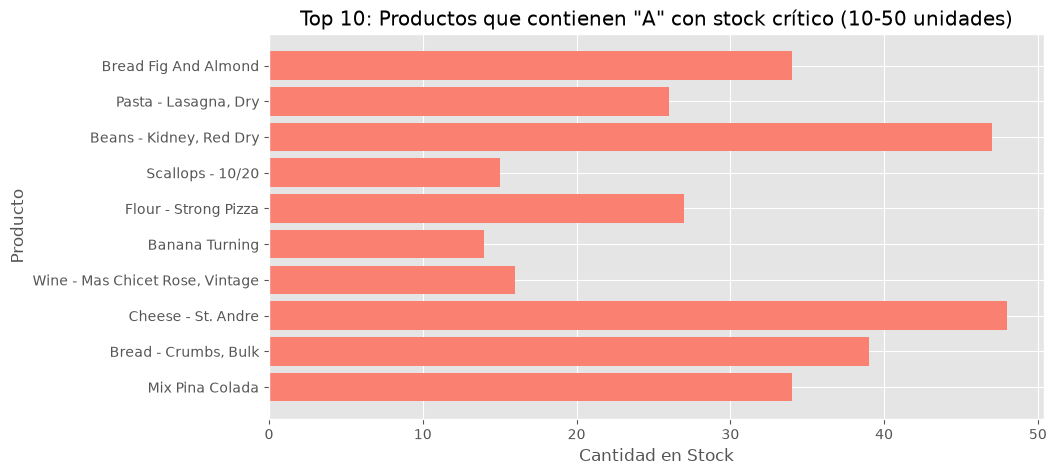

,nombre,stock
0,Bread Fig And Almond,34
1,"Pasta - Lasagna, Dry",26
2,"Beans - Kidney, Red Dry",47
3,Scallops - 10/20,15
4,Flour - Strong Pizza,27
5,Banana Turning,14
6,"Wine - Mas Chicet Rose, Vintage",16
7,Cheese - St. Andre,48
8,"Bread - Crumbs, Bulk",39
9,Mix Pina Colada,34


In [14]:
query_1 = """
SELECT nombre, stock 
FROM productos 
WHERE stock BETWEEN 10 AND 50 
AND nombre LIKE '%a%'
LIMIT 10; -- Limitamos a 10 para que el gráfico sea legible
"""
df_q1 = pd.read_sql(query_1, conexion)

# Gráfico de barras horizontales
plt.figure(figsize=(10, 5))
plt.barh(df_q1['nombre'], df_q1['stock'], color='salmon')
plt.title('Top 10: Productos que contienen "A" con stock crítico (10-50 unidades)')
plt.xlabel('Cantidad en Stock')
plt.ylabel('Producto')
plt.gca().invert_yaxis() # Invertir eje para que el que más tiene quede arriba
plt.show()

display(df_q1)

# Consulta 2 - Capital Invertido por Categoría (GROUP BY, COUNT, AVG, SUM)


Vamos a cruzar la tabla de productos con la de categorías para saber cuántos productos hay, el precio promedio y el capital total invertido (precio * stock) por categoría.

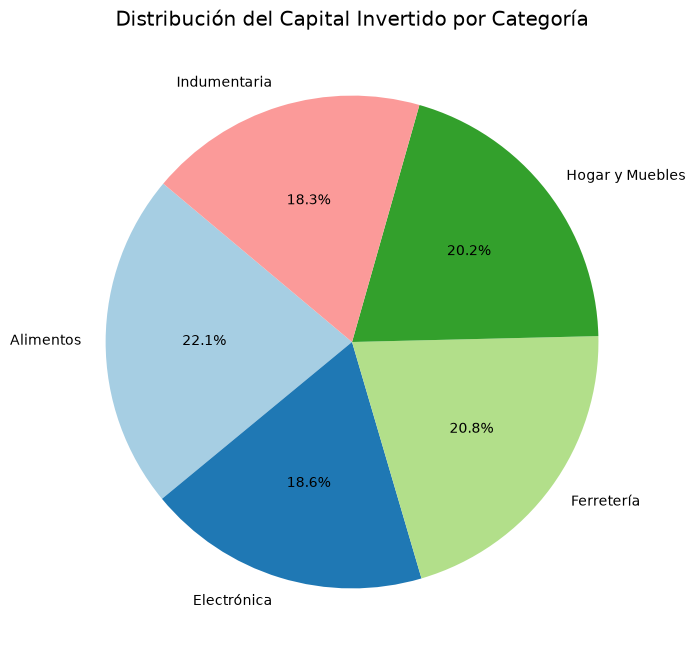

,nombre_categoria,cantidad_productos,precio_promedio,capital_invertido
0,Alimentos,227,51213.731278,1.632964e+09
1,Electrónica,210,46380.938095,1.372416e+09
2,Ferretería,207,49373.178744,1.539962e+09
3,Hogar y Muebles,186,52159.516129,1.493881e+09
4,Indumentaria,170,49662.729412,1.352430e+09


In [15]:
query_2 = """
SELECT 
    c.nombre_categoria,
    COUNT(p.id_producto) as cantidad_productos,
    AVG(p.precio) as precio_promedio,
    SUM(p.precio * p.stock) as capital_invertido
FROM productos p
JOIN categorias c ON p.categoria_id = c.id_categoria
GROUP BY c.nombre_categoria;
"""
df_q2 = pd.read_sql(query_2, conexion)

# Gráfico de torta (Pie chart) para ver dónde está el mayor capital
plt.figure(figsize=(8, 8))
plt.pie(df_q2['capital_invertido'], labels=df_q2['nombre_categoria'], autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
plt.title('Distribución del Capital Invertido por Categoría')
plt.show()

display(df_q2)

## Consulta 3 - Reporte Gerencial de Extremos (MIN, MAX, CONCAT)

Generamos un reporte formateado directamente desde el motor SQL con los valores más extremos del inventario.